# Lab 10-03 · BJT DC Operation and Biasing

Companion to [chapter 10-03](../../chapters/10-03-bjt-dc-operation-and-biasing.md). Predict first; the `assert` lines check against the answer keys.

In [1]:
import math
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import brentq
from scipy.integrate import solve_ivp
VT = 1.380649e-23 * 300 / 1.602176634e-19

def four_resistor(beta, vbe=0.7, vcc=12, r1=47e3, r2=10e3, re=1e3, rc=4.7e3):
    vth, rth = vcc * r2 / (r1 + r2), r1 * r2 / (r1 + r2)
    ie = (vth - vbe) / (re + rth / (beta + 1))
    ic = ie * beta / (beta + 1)
    return ic, vcc - rc * ic - re * ie            # I_C and V_CE

## Part 1 · β sweep through three bias networks

*Predict first:* which network saturates first as β rises?

base current      : saturates at beta = 181
collector feedback: never saturates up to 400
four-resistor     : never saturates up to 400


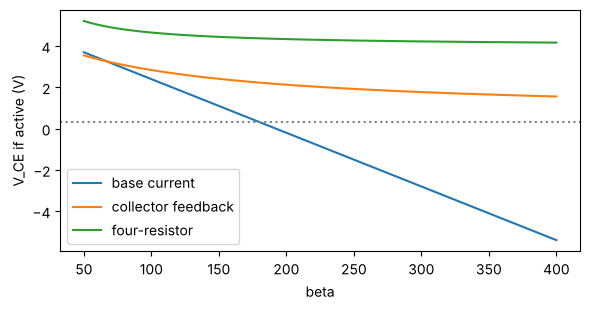

In [2]:
betas = np.linspace(50, 400, 351)
base = np.array([b * 13e-6 for b in betas]); vce_base = 5 - 2e3 * base
fb = np.array([(5 - 0.7) / (2e3 + 200e3 / (b + 1)) * b / (b + 1) for b in betas])
vce_fb = np.array([5 - 2e3 * (5 - 0.7) / (2e3 + 200e3 / (b + 1)) for b in betas])
four = np.array([four_resistor(b)[0] for b in betas]); vce_four = np.array([four_resistor(b)[1] for b in betas])
for name, vce in (("base current", vce_base), ("collector feedback", vce_fb), ("four-resistor", vce_four)):
    sat = betas[vce < 0.3]
    print(f"{name:18s}: saturates at beta = {sat[0]:.0f}" if len(sat) else f"{name:18s}: never saturates up to 400")
plt.figure(figsize=(6, 3.2))
plt.plot(betas, vce_base, label="base current"); plt.plot(betas, vce_fb, label="collector feedback")
plt.plot(betas, vce_four, label="four-resistor"); plt.axhline(0.3, ls=":", color="0.5")
plt.xlabel("beta"); plt.ylabel("V_CE if active (V)"); plt.legend(); plt.tight_layout(); plt.show()

## Part 2 · Monte Carlo of β and V_BE (guided exercise)

*Predict first:* the ratio of the largest to the smallest collector current.

max/min = 1.0894, sigma = 1.757%, mean = 1.3376 mA


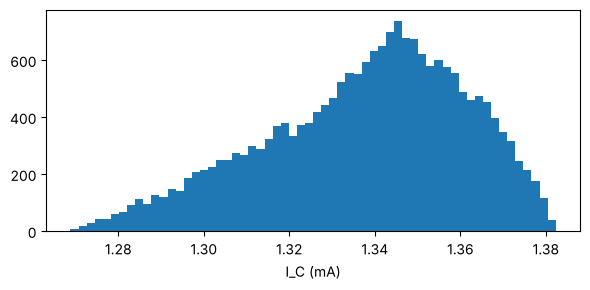

In [3]:
rng = np.random.default_rng(1003)
b = rng.uniform(100, 300, 20000); x = 0.7 + rng.uniform(-0.02, 0.02, 20000)
ic = np.array([four_resistor(bb, xx)[0] for bb, xx in zip(b, x)])
print(f"max/min = {ic.max()/ic.min():.4f}, sigma = {ic.std()/ic.mean()*100:.3f}%, mean = {ic.mean()*1e3:.4f} mA")
assert abs(ic.max() / ic.min() - 1.089) < 5e-4 and abs(ic.std() / ic.mean() * 100 - 1.76) < 5e-3
assert abs(ic.mean() * 1e3 - 1.338) < 5e-4
plt.figure(figsize=(6, 3)); plt.hist(ic * 1e3, bins=60); plt.xlabel("I_C (mA)"); plt.tight_layout(); plt.show()

## Part 3 · Thermal runaway

A transistor with $V_{CE}$ = 5 V, $R_{\theta JA}$ = 200 K/W and a thermal time constant of 10 s, base voltage fixed at its cold value. Below about 12.9 mA (Problem 10-03.10) the self-heating settles; above, it does not.

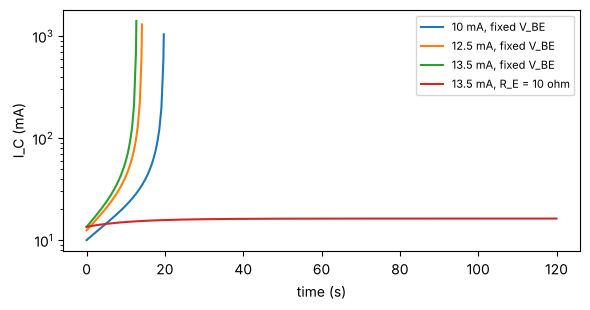

In [4]:
def run(i0, re=0.0, tau=10.0, t_end=120):
    vb = VT * math.log(i0 / 1e-15) + i0 * re
    def ic(dT):
        dT = min(max(dT, -50.0), 100.0)                      # keep trial steps in a physical range
        return brentq(lambda i: VT * math.log(i / 1e-15) - 0.002 * dT + i * re - vb, 1e-9, 1e6)
    def rhs(t, y):
        i = ic(y[0])
        return [(5 * i * 200 - y[0]) / tau]
    ev = lambda t, y: y[0] - 60; ev.terminal = True        # stop at a 60 K rise
    sol = solve_ivp(rhs, (0, t_end), [0.0], max_step=0.5, events=ev)
    return sol.t, [ic(T) for T in sol.y[0]]
plt.figure(figsize=(6, 3.2))
for i0, re, lab in ((0.010, 0, "10 mA, fixed V_BE"), (0.0125, 0, "12.5 mA, fixed V_BE"), (0.0135, 0, "13.5 mA, fixed V_BE"),
                    (0.0135, 10.0, "13.5 mA, R_E = 10 ohm")):
    t, i = run(i0, re)
    plt.plot(t, np.array(i) * 1e3, label=lab)
plt.yscale("log"); plt.xlabel("time (s)"); plt.ylabel("I_C (mA)"); plt.legend(fontsize=8); plt.tight_layout(); plt.show()

## Part 4 · Storage delay of a saturated switch

Charge-control (09-07): in saturation the excess base charge $Q_S$ obeys $dQ_S/dt = I_B - I_C/\beta - Q_S/\tau_S$. Take $\tau_S$ = 50 ns, β = 100, $I_C$ = 10 mA; at $t$ = 0 the base drive reverses to $-I_B/2$, and the collector current starts falling only when $Q_S$ reaches zero.

In [5]:
tauS, beta, IC = 50e-9, 100, 10e-3
for fb in (10, 3):
    IB = IC / fb
    QS0 = (IB - IC / beta) * tauS                    # steady state before turn-off
    # dQ/dt = -IB/2 - IC/beta - Q/tauS  -> time to reach Q = 0
    a = -IB / 2 - IC / beta
    ts = tauS * math.log((QS0 - a * tauS) / (-a * tauS))
    print(f"forced beta {fb:2d}: stored charge {QS0*1e12:.1f} pC, storage delay {ts*1e9:.1f} ns")

forced beta 10: stored charge 45.0 pC, storage delay 45.8 ns
forced beta  3: stored charge 161.7 pC, storage delay 52.0 ns
